# Comparing Solutions to Spam Email Detections

- Author: Jovan Heng Ghim Hong


**Goal:** Can simple models like BoW/TF-IDF + MLP outperform complex models like BERT + LSTM for spam email detection?

**How is comparison done?**

- We evaluate the following metrics
  - Recall (Spm Detection Rate)
  - Model Size
  - Training Time

- Note that all models are trained and evaluated on the same dataset for a fair comparison.

## BoW and TF-IDF Implementation for Spam Email Detection

I want to try to build a simple spam email detector. For now I will try to implement BoW and TF-IDF as a more lightweight alternative to word embeddings.

Since BoW and TF-IDF remove word order, a simple MLP should be sufficient, removing the need for a order based RNN like LSTM or GRU.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
#imports
import random
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import warnings
warnings.filterwarnings("ignore")

import torch
import torch.nn as nn
from torch.optim import Adam
from torch.utils.data import DataLoader, TensorDataset

torch.manual_seed(42)
np.random.seed(42)

from sklearn.model_selection import train_test_split, StratifiedKFold, ParameterSampler
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, confusion_matrix, recall_score

from nltk.tokenize import word_tokenize

from src.eda import clean_text, remove_stopwords, lemmatize_reviews
from src.utils import timer
from src.model import Model, train_kf

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\JOVAN\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!


In [3]:
# import the dataset
data = pd.read_csv('dataset/email.csv')
X = data['Message'].values
y = [0 if l == 'ham' else 1 for l in data['Category'].values]

X_train , X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [4]:
# here we clean the text and prepare it for vectorization
X_train = [remove_stopwords(clean_text(text)) for text in X_train]
X_test = [remove_stopwords(clean_text(text)) for text in X_test]

# for a simple model like BoW or TF-IDF lemmatization typically helps
X_train_lematized = [lemmatize_reviews(text) for text in X_train]
X_test_lematized = [lemmatize_reviews(text) for text in X_test]

In [5]:
_ , (ham_count, spam_count) = np.unique(y_train, return_counts=True)
print(f'Ham Count: {ham_count/len(y_train)*100:.2f}%')
print(f'Spam Count: {spam_count/len(y_train)*100:.2f}%')

Ham Count: 86.59%
Spam Count: 13.41%


In [6]:
# we will use class weights to handle class imbalance
class_weights = torch.tensor([len(y_train)/(2*ham_count), len(y_train)/(2*spam_count)], dtype=torch.float)

### Binary Bag of Words

In [19]:
# we will still try to implement on a lemmatized dataset with both BoW and TF-IDF
bow_vectorizer = CountVectorizer(tokenizer=word_tokenize, binary=True, lowercase=True, max_features=5000, ngram_range=(1,2))
X_sequences = bow_vectorizer.fit_transform(X_train)
X_test_sequences = bow_vectorizer.transform(X_test)

X_lemmatized_sequences = bow_vectorizer.fit_transform(X_train_lematized)
X_test_lemmatized_sequences = bow_vectorizer.transform(X_test_lematized)

In [20]:
## Prepare DataLoaders
## Original
binary_bow_x_train = TensorDataset(torch.tensor(X_sequences.toarray(), dtype=torch.float32), torch.tensor(y_train))
binary_bow_x_test = TensorDataset(torch.tensor(X_test_sequences.toarray(), dtype=torch.float32), torch.tensor(y_test))

binary_bow_x_train_loader = DataLoader(binary_bow_x_train, batch_size=32, shuffle=True)
binary_bow_x_test_loader = DataLoader(binary_bow_x_test, batch_size=32)

## lematized
# in theory lematization should help with BoW/TF-IDF
binary_bow_lematized_x_train = TensorDataset(torch.tensor(X_lemmatized_sequences.toarray(), dtype=torch.float32), torch.tensor(y_train))
binary_bow_lematized_x_test = TensorDataset(torch.tensor(X_test_lemmatized_sequences.toarray(), dtype=torch.float32), torch.tensor(y_test))

binary_bow_lematized_x_train_loader = DataLoader(binary_bow_lematized_x_train, batch_size=32, shuffle=True)
binary_bow_lematized_x_test_loader = DataLoader(binary_bow_lematized_x_test, batch_size=32)

In [28]:
# we build a simple linear model
class LinearModel(Model):
  def __init__(self, input_dim, hidden_dim, output_dim, dropout_rate=0.5):
    super().__init__()
    # since the inputs are BoW/TF-IDF vectors, we can use a simple feedforward neural network
    self.fc1 = nn.Linear(input_dim, hidden_dim)
    self.relu = nn.ReLU()
    self.dropout = nn.Dropout(dropout_rate)
    self.fc2 = nn.Linear(hidden_dim, output_dim)
    self.accuracy_history = []
    self.loss_history = []
  
  def forward(self, x):
    out = self.fc1(x)
    out = self.relu(out)
    out = self.fc2(out)
    return out


In [10]:
# here we will define a hyper parameter space for the MLP

param_space = {
    'input_dim': [X_sequences.shape[1], X_lemmatized_sequences.shape[1]],
    'hidden_dim': [4, 8, 16, 32],
    'output_dim': [2],
    'lr': [1e-2, 1e-3, 1e-4],
    'batch_size': [16, 32, 64, 128],
    'epochs': [10, 20, 30, 40],
    'dropout_rate': [0.3, 0.5, 0.7]
}

selected_params = list(ParameterSampler(param_space, n_iter=10, random_state=42))

In [11]:
# we will train 2 models: one on the original data and one on the lemmatized data
# we will be using stratified kf cv

# prevent rerunning
# original_data
binary_bow_results = []
kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
for params in selected_params:
  print(f'Training Binary BoW with params: {params}')


  model = LinearModel
  optimizer = Adam
  loss_fn = nn.CrossEntropyLoss(weight=class_weights)
  results = train_kf(
    model,
    params={
      'input_dim': params['input_dim'],
      'hidden_dim': params['hidden_dim'],
      'output_dim': params['output_dim'],
      'dropout_rate': params['dropout_rate']
    },
    train_loader=binary_bow_x_train_loader,
    loss_fn=loss_fn,
    optimizer=optimizer,
    kf=kf,
    batch_size=params['batch_size'],
    epochs=params['epochs'],
    early_stop=True,
    patience=5
)

  binary_bow_results.append({
    **params,
    **results
  })

  
# lemmatized data
lemmatized_bow_results = []
for params in selected_params:
  print(f'Training Binary BoW Lemmatized with params: {params}')
  model = LinearModel
  optimizer = Adam
  loss_fn = nn.CrossEntropyLoss(weight=class_weights)
  results = train_kf(
    model,
    params={
      'input_dim': params['input_dim'],
      'hidden_dim': params['hidden_dim'],
      'output_dim': params['output_dim'],
      'dropout_rate': params['dropout_rate']
    },
    train_loader=binary_bow_lematized_x_train_loader,
    loss_fn=loss_fn,
    optimizer=optimizer,
    kf=kf,
    batch_size=params['batch_size'],
    epochs=params['epochs'],
    early_stop=True,
    patience=5
)

  lemmatized_bow_results.append({
    **params,
    **results
  })

Training Binary BoW with params: {'output_dim': 2, 'lr': 0.001, 'input_dim': 5000, 'hidden_dim': 32, 'epochs': 30, 'dropout_rate': 0.7, 'batch_size': 128}

Fold 1/5
Epoch 1/30, Loss: 0.6355, Accuracy: 52.47%
Epoch 2/30, Loss: 0.4240, Accuracy: 96.75%
Epoch 3/30, Loss: 0.2428, Accuracy: 98.60%
Epoch 4/30, Loss: 0.1505, Accuracy: 98.99%
Epoch 5/30, Loss: 0.1042, Accuracy: 99.30%
Epoch 6/30, Loss: 0.0766, Accuracy: 99.58%
Epoch 7/30, Loss: 0.0604, Accuracy: 99.64%
Epoch 8/30, Loss: 0.0486, Accuracy: 99.69%
Epoch 9/30, Loss: 0.0409, Accuracy: 99.72%
Epoch 10/30, Loss: 0.0359, Accuracy: 99.75%
Epoch 11/30, Loss: 0.0312, Accuracy: 99.78%
Epoch 12/30, Loss: 0.0275, Accuracy: 99.80%
Epoch 13/30, Loss: 0.0242, Accuracy: 99.80%
Epoch 14/30, Loss: 0.0222, Accuracy: 99.83%
Epoch 15/30, Loss: 0.0204, Accuracy: 99.83%
Epoch 16/30, Loss: 0.0190, Accuracy: 99.83%
Epoch 17/30, Loss: 0.0179, Accuracy: 99.86%
Epoch 18/30, Loss: 0.0164, Accuracy: 99.86%
Epoch 19/30, Loss: 0.0160, Accuracy: 99.89%
Epoch 20

In [12]:
binary_bow_results_df = pd.DataFrame(binary_bow_results).sort_values(by='f1', ascending=False)
lemmatized_bow_results_df = pd.DataFrame(lemmatized_bow_results).sort_values(by='f1', ascending=False)

binary_bow_results_df.to_csv('results/binary_bow_results.csv', index=False)
lemmatized_bow_results_df.to_csv('results/lemmatized_bow_results.csv', index=False)

display(binary_bow_results_df)
display(lemmatized_bow_results_df)

,output_dim,lr,input_dim,hidden_dim,epochs,dropout_rate,batch_size,recall,precision,f1,accuracy
3,2,0.0100,5000,16,20,0.7,128,0.949311,0.977369,0.962672,0.983176
9,2,0.0010,5000,32,30,0.7,128,0.945634,0.980131,0.961938,0.982952
0,2,0.0010,5000,32,30,0.7,128,0.946797,0.976932,0.961117,0.982504
4,2,0.0100,5000,16,40,0.5,128,0.945956,0.976857,0.960598,0.982279
5,2,0.0010,5000,4,20,0.5,16,0.943306,0.975504,0.958510,0.981382
2,2,0.0001,5000,4,40,0.7,128,0.941058,0.976919,0.957633,0.981157
7,2,0.0100,5000,32,20,0.3,32,0.940792,0.974920,0.956918,0.980708
1,2,0.0001,5000,32,40,0.7,64,0.943117,0.968704,0.955335,0.979812
6,2,0.0010,5000,8,40,0.5,32,0.942276,0.968548,0.954800,0.979588
8,2,0.0100,5000,16,40,0.3,16,0.938166,0.962753,0.949948,0.977345


,output_dim,lr,input_dim,hidden_dim,epochs,dropout_rate,batch_size,recall,precision,f1,accuracy
4,2,0.0100,5000,16,40,0.5,128,0.945841,0.975857,0.960124,0.982055
0,2,0.0010,5000,32,30,0.7,128,0.945575,0.974183,0.959209,0.981607
3,2,0.0100,5000,16,20,0.7,128,0.944885,0.974939,0.959129,0.981607
9,2,0.0010,5000,32,30,0.7,128,0.945445,0.973291,0.958730,0.981382
2,2,0.0001,5000,4,40,0.7,128,0.947462,0.970493,0.958429,0.981158
5,2,0.0010,5000,4,20,0.5,16,0.941544,0.974214,0.956978,0.980710
7,2,0.0100,5000,32,20,0.3,32,0.941580,0.969150,0.954740,0.979588
1,2,0.0001,5000,32,40,0.7,64,0.942161,0.967607,0.954350,0.979363
6,2,0.0010,5000,8,40,0.5,32,0.944738,0.963366,0.953695,0.978915
8,2,0.0100,5000,16,40,0.3,16,0.931188,0.949294,0.939869,0.972634


In [13]:
# retraining on the best params
print('Training Baseline BoW Model')
with timer('Baseline BoW Model Training Time'):
  bow_best_params = binary_bow_results_df.iloc[0]

  # need to rebatch the data
  binary_bow_x_train_loader = DataLoader(binary_bow_x_train, batch_size=int(bow_best_params['batch_size']), shuffle=True)

  bow_best_model = LinearModel(
    input_dim=int(bow_best_params['input_dim']),
    hidden_dim=int(bow_best_params['hidden_dim']),
    output_dim=int(bow_best_params['output_dim']),
    dropout_rate=float(bow_best_params['dropout_rate'])
  )
  optimizer = Adam(bow_best_model.parameters(), lr=bow_best_params['lr'])
  bow_best_model.fit(int(bow_best_params['epochs']), binary_bow_x_train_loader, loss_fn, optimizer, early_stop=True)

print()
print('Training Baseline Lemmatized BoW Model')
with timer('Baseline Lemmatized BoW Model Training Time'):
  lemmatized_bow_best_params = lemmatized_bow_results_df.iloc[0]

  # need to rebatch the data
  binary_bow_lematized_x_train_loader = DataLoader(binary_bow_lematized_x_train, batch_size=int(lemmatized_bow_best_params['batch_size']), shuffle=True)

  lemmatized_bow_best_model = LinearModel(
    input_dim=int(lemmatized_bow_best_params['input_dim']),
    hidden_dim=int(lemmatized_bow_best_params['hidden_dim']),
    output_dim=int(lemmatized_bow_best_params['output_dim']),
    dropout_rate=float(lemmatized_bow_best_params['dropout_rate'])
  )
  optimizer = Adam(lemmatized_bow_best_model.parameters(), lr=lemmatized_bow_best_params['lr'])
  lemmatized_bow_best_model.fit(int(lemmatized_bow_best_params['epochs']), binary_bow_lematized_x_train_loader, loss_fn, optimizer, early_stop=True)

Training Baseline BoW Model
Epoch 1/20, Loss: 0.3152, Accuracy: 93.52%
Epoch 2/20, Loss: 0.0544, Accuracy: 98.83%
Epoch 3/20, Loss: 0.0241, Accuracy: 99.71%
Epoch 4/20, Loss: 0.0153, Accuracy: 99.80%
Epoch 5/20, Loss: 0.0114, Accuracy: 99.91%
Epoch 6/20, Loss: 0.0098, Accuracy: 99.93%
Epoch 7/20, Loss: 0.0091, Accuracy: 99.93%
Epoch 8/20, Loss: 0.0081, Accuracy: 99.93%
Epoch 9/20, Loss: 0.0084, Accuracy: 99.93%
Epoch 10/20, Loss: 0.0078, Accuracy: 99.93%
Epoch 11/20, Loss: 0.0073, Accuracy: 99.93%
Epoch 12/20, Loss: 0.0065, Accuracy: 99.93%
Epoch 13/20, Loss: 0.0066, Accuracy: 99.96%
Epoch 14/20, Loss: 0.0069, Accuracy: 99.96%
Epoch 15/20, Loss: 0.0064, Accuracy: 99.96%
Epoch 16/20, Loss: 0.0067, Accuracy: 99.96%
Epoch 17/20, Loss: 0.0064, Accuracy: 99.96%
Epoch 18/20, Loss: 0.0055, Accuracy: 99.96%
Epoch 19/20, Loss: 0.0054, Accuracy: 99.96%
Epoch 20/20, Loss: 0.0060, Accuracy: 99.96%
Baseline BoW Model Training Time: 2.0424s

Training Baseline Lemmatized BoW Model
Epoch 1/40, Loss: 0

In [14]:
# saving weights
torch.save(bow_best_model.state_dict(), 'weights/bow_model.pth')
torch.save(lemmatized_bow_best_model.state_dict(), 'weights/lemmatized_bow_model.pth')

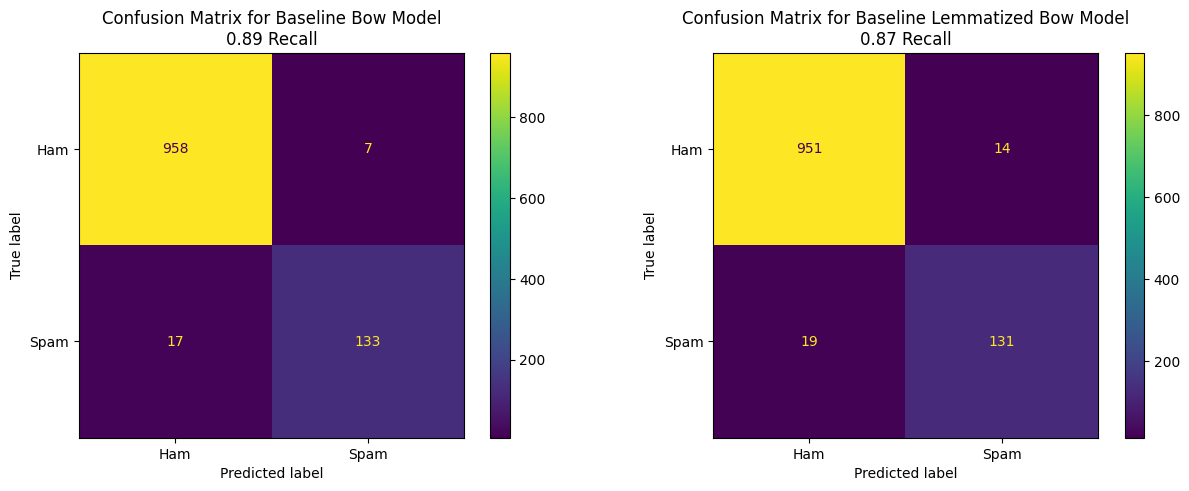

In [22]:
# loading weights
bow_best_params = pd.read_csv('results/binary_bow_results.csv').sort_values(by='f1', ascending=False).iloc[0]
lemmatized_bow_best_params = pd.read_csv('results/lemmatized_bow_results.csv').sort_values(by='f1', ascending=False).iloc[0]
bow_best_model = LinearModel(
  input_dim=int(bow_best_params['input_dim']),
  hidden_dim=int(bow_best_params['hidden_dim']),
  output_dim=int(bow_best_params['output_dim']),
  dropout_rate=float(bow_best_params['dropout_rate'])
)
lemmatized_bow_best_model = LinearModel(
  input_dim=int(lemmatized_bow_best_params['input_dim']),
  hidden_dim=int(lemmatized_bow_best_params['hidden_dim']),
  output_dim=int(lemmatized_bow_best_params['output_dim']),
  dropout_rate=float(lemmatized_bow_best_params['dropout_rate'])
)

bow_best_model.load_state_dict(torch.load('weights/bow_model.pth'))
lemmatized_bow_best_model.load_state_dict(torch.load('weights/lemmatized_bow_model.pth'))

# get predictions (on test set)
baseline_bow_predictions = bow_best_model.predict(binary_bow_x_test_loader)
baseline_bow_lematized_predictions = lemmatized_bow_best_model.predict(binary_bow_lematized_x_test_loader)

# plot cms
fig , axes = plt.subplots(1, 2, figsize=(15, 5))

# non lemmatized
baseline_bow_cm = confusion_matrix(y_test, baseline_bow_predictions)
disp = ConfusionMatrixDisplay(confusion_matrix=baseline_bow_cm, display_labels=['Ham', 'Spam'])
disp.plot(ax=axes[0])
axes[0].set_title(f'Confusion Matrix for Baseline Bow Model\n{recall_score(y_test, baseline_bow_predictions, pos_label=1):.2f} Recall')

# lemmatized
baseline_bow_lematized_cm = confusion_matrix(y_test, baseline_bow_lematized_predictions)
disp_lematized = ConfusionMatrixDisplay(confusion_matrix=baseline_bow_lematized_cm, display_labels=['Ham', 'Spam'])
disp_lematized.plot(ax=axes[1])
axes[1].set_title(f'Confusion Matrix for Baseline Lemmatized Bow Model\n{recall_score(y_test, baseline_bow_lematized_predictions, pos_label=1):.2f} Recall')

plt.show()

Here we see that such a simple model such as Binary BoW with a simple MLP can achieve a high recall on the spam emails.

The results here also show that lemmatization has almost no impact


--- 

### TF-IDF

In theory since TF-IDF takes into account word importance, it should perform better than BoW. 

In [23]:
tf_idf_vectorizer = TfidfVectorizer(tokenizer=word_tokenize, lowercase=True, max_features=5000, ngram_range=(1,2))
X_sequences = tf_idf_vectorizer.fit_transform(X_train)
X_test_sequences = tf_idf_vectorizer.transform(X_test)

X_lemmatized_sequences = tf_idf_vectorizer.fit_transform(X_train_lematized)
X_test_lemmatized_sequences = tf_idf_vectorizer.transform(X_test_lematized)

In [24]:
## Prepare DataLoaders
## Original
tf_idf_x_train = TensorDataset(torch.tensor(X_sequences.toarray(), dtype=torch.float32), torch.tensor(y_train))
tf_idf_x_test = TensorDataset(torch.tensor(X_test_sequences.toarray(), dtype=torch.float32), torch.tensor(y_test))

tf_idf_x_train_loader = DataLoader(tf_idf_x_train, batch_size=32, shuffle=True)
tf_idf_x_test_loader = DataLoader(tf_idf_x_test, batch_size=32)

## lematized
tf_idf_lematized_x_train = TensorDataset(torch.tensor(X_lemmatized_sequences.toarray(), dtype=torch.float32), torch.tensor(y_train))
tf_idf_lematized_x_test = TensorDataset(torch.tensor(X_test_lemmatized_sequences.toarray(), dtype=torch.float32), torch.tensor(y_test))

tf_idf_lematized_x_train_loader = DataLoader(tf_idf_lematized_x_train, batch_size=32, shuffle=True)
tf_idf_lematized_x_test_loader = DataLoader(tf_idf_lematized_x_test, batch_size=32)

In [18]:
# prevent rerunning
# hyperparameter tuning for TF-IDF models (original and lemmatized)
tf_idf_results = []
kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
for params in selected_params:
  print(f'Training TF-IDF with params: {params}')

  model = LinearModel
  optimizer = Adam
  loss_fn = nn.CrossEntropyLoss(weight=class_weights)
  results = train_kf(
    model,
    params={
      'input_dim': params['input_dim'],
      'hidden_dim': params['hidden_dim'],
      'output_dim': params['output_dim'],
      'dropout_rate': params['dropout_rate']
    },
    train_loader=tf_idf_x_train_loader,
    loss_fn=loss_fn,
    optimizer=optimizer,
    kf=kf,
    batch_size=params['batch_size'],
    epochs=params['epochs'],
    early_stop=True,
    patience=5
  )

  tf_idf_results.append({
    **params,
    **results
  })

# lemmatized data
tf_idf_lematized_results = []
for params in selected_params:
  print(f'Training TF-IDF Lemmatized with params: {params}')
  model = LinearModel
  optimizer = Adam
  loss_fn = nn.CrossEntropyLoss(weight=class_weights)
  results = train_kf(
    model,
    params={
      'input_dim': params['input_dim'],
      'hidden_dim': params['hidden_dim'],
      'output_dim': params['output_dim'],
      'dropout_rate': params['dropout_rate']
    },
    train_loader=tf_idf_lematized_x_train_loader,
    loss_fn=loss_fn,
    optimizer=optimizer,
    kf=kf,
    batch_size=params['batch_size'],
    epochs=params['epochs'],
    early_stop=True,
    patience=5
  )

  tf_idf_lematized_results.append({
    **params,
    **results
  })

Training TF-IDF with params: {'output_dim': 2, 'lr': 0.001, 'input_dim': 5000, 'hidden_dim': 32, 'epochs': 30, 'dropout_rate': 0.7, 'batch_size': 128}

Fold 1/5
Epoch 1/30, Loss: 0.6769, Accuracy: 33.99%
Epoch 2/30, Loss: 0.5906, Accuracy: 93.16%
Epoch 3/30, Loss: 0.4513, Accuracy: 96.13%
Epoch 4/30, Loss: 0.3143, Accuracy: 97.42%
Epoch 5/30, Loss: 0.2164, Accuracy: 98.26%
Epoch 6/30, Loss: 0.1552, Accuracy: 98.85%
Epoch 7/30, Loss: 0.1181, Accuracy: 99.02%
Epoch 8/30, Loss: 0.0939, Accuracy: 99.27%
Epoch 9/30, Loss: 0.0763, Accuracy: 99.36%
Epoch 10/30, Loss: 0.0628, Accuracy: 99.44%
Epoch 11/30, Loss: 0.0539, Accuracy: 99.52%
Epoch 12/30, Loss: 0.0467, Accuracy: 99.61%
Epoch 13/30, Loss: 0.0407, Accuracy: 99.61%
Epoch 14/30, Loss: 0.0359, Accuracy: 99.64%
Epoch 15/30, Loss: 0.0324, Accuracy: 99.69%
Epoch 16/30, Loss: 0.0292, Accuracy: 99.78%
Epoch 17/30, Loss: 0.0265, Accuracy: 99.80%
Epoch 18/30, Loss: 0.0244, Accuracy: 99.80%
Epoch 19/30, Loss: 0.0225, Accuracy: 99.83%
Epoch 20/30,

In [19]:
tf_idf_results_df = pd.DataFrame(tf_idf_results).sort_values(by='f1', ascending=False)
tf_idf_lematized_results_df = pd.DataFrame(tf_idf_lematized_results).sort_values(by='f1', ascending=False)

tf_idf_results_df.to_csv('results/tf_idf_results.csv', index=False)
tf_idf_lematized_results_df.to_csv('results/lemmatized_tf_idf_results.csv', index=False)

display(tf_idf_results_df)
display(tf_idf_lematized_results_df)

,output_dim,lr,input_dim,hidden_dim,epochs,dropout_rate,batch_size,recall,precision,f1,accuracy
4,2,0.0100,5000,16,40,0.5,128,0.951870,0.962642,0.957070,0.980261
7,2,0.0100,5000,32,20,0.3,32,0.951167,0.963317,0.957024,0.980261
0,2,0.0010,5000,32,30,0.7,128,0.951037,0.962470,0.956544,0.980037
9,2,0.0010,5000,32,30,0.7,128,0.950778,0.960944,0.955646,0.979588
5,2,0.0010,5000,4,20,0.5,16,0.944517,0.967263,0.955460,0.979811
6,2,0.0010,5000,8,40,0.5,32,0.949808,0.959855,0.954665,0.979140
1,2,0.0001,5000,32,40,0.7,64,0.948709,0.958216,0.953283,0.978467
2,2,0.0001,5000,4,40,0.7,128,0.945204,0.961750,0.952816,0.978467
3,2,0.0100,5000,16,20,0.7,128,0.949749,0.954661,0.952012,0.977793
8,2,0.0100,5000,16,40,0.3,16,0.948887,0.954448,0.951514,0.977568


,output_dim,lr,input_dim,hidden_dim,epochs,dropout_rate,batch_size,recall,precision,f1,accuracy
4,2,0.0100,5000,16,40,0.5,128,0.954766,0.965408,0.959952,0.981606
0,2,0.0010,5000,32,30,0.7,128,0.954636,0.964657,0.959502,0.981382
9,2,0.0010,5000,32,30,0.7,128,0.955211,0.963230,0.959114,0.981157
5,2,0.0010,5000,4,20,0.5,16,0.952963,0.964338,0.958468,0.980933
7,2,0.0100,5000,32,20,0.3,32,0.954563,0.959224,0.956837,0.980036
2,2,0.0001,5000,4,40,0.7,128,0.953026,0.959778,0.956253,0.979812
3,2,0.0100,5000,16,20,0.7,128,0.952896,0.958921,0.955788,0.979587
6,2,0.0010,5000,8,40,0.5,32,0.951489,0.960087,0.955673,0.979588
1,2,0.0001,5000,32,40,0.7,64,0.953082,0.955141,0.954053,0.978691
8,2,0.0100,5000,16,40,0.3,16,0.949273,0.946997,0.948047,0.975774


In [20]:
print('Training Baseline TF-IDF Model')
with timer('Baseline TF-IDF Model Training Time'):
  tf_idf_best_params = tf_idf_results_df.iloc[0]

  # rebatch with best batch size
  tf_idf_x_train_loader = DataLoader(tf_idf_x_train, batch_size=int(tf_idf_best_params['batch_size']), shuffle=True)

  tf_idf_model = LinearModel(
    input_dim=int(tf_idf_best_params['input_dim']),
    hidden_dim=int(tf_idf_best_params['hidden_dim']),
    output_dim=int(tf_idf_best_params['output_dim']),
    dropout_rate=float(tf_idf_best_params['dropout_rate'])
  )
  tf_idf_optimizer = Adam(tf_idf_model.parameters(), lr=tf_idf_best_params['lr'])
  tf_idf_model.fit(int(tf_idf_best_params['epochs']), tf_idf_x_train_loader, loss_fn, tf_idf_optimizer, early_stop=True)

print()
print('Training Baseline Lemmatized TF-IDF Model')
with timer('Baseline Lemmatized TF-IDF Model Training Time'):
  tf_idf_lemmatized_best_params = tf_idf_lematized_results_df.iloc[0]

  # rebatch with best batch size
  tf_idf_lematized_x_train_loader = DataLoader(tf_idf_lematized_x_train, batch_size=int(tf_idf_lemmatized_best_params['batch_size']), shuffle=True)

  tf_idf_lemmatized_model = LinearModel(
    input_dim=int(tf_idf_lemmatized_best_params['input_dim']),
    hidden_dim=int(tf_idf_lemmatized_best_params['hidden_dim']),
    output_dim=int(tf_idf_lemmatized_best_params['output_dim']),
    dropout_rate=float(tf_idf_lemmatized_best_params['dropout_rate'])
  )
  tf_idf_lemmatized_optimizer = Adam(tf_idf_lemmatized_model.parameters(), lr=tf_idf_lemmatized_best_params['lr'])
  tf_idf_lemmatized_model.fit(int(tf_idf_lemmatized_best_params['epochs']), tf_idf_lematized_x_train_loader, loss_fn, tf_idf_lemmatized_optimizer, early_stop=True)

Training Baseline TF-IDF Model
Epoch 1/40, Loss: 0.4262, Accuracy: 93.29%
Epoch 2/40, Loss: 0.0761, Accuracy: 98.30%
Epoch 3/40, Loss: 0.0295, Accuracy: 99.51%
Epoch 4/40, Loss: 0.0156, Accuracy: 99.80%
Epoch 5/40, Loss: 0.0109, Accuracy: 99.84%
Epoch 6/40, Loss: 0.0091, Accuracy: 99.93%
Epoch 7/40, Loss: 0.0079, Accuracy: 99.93%
Epoch 8/40, Loss: 0.0068, Accuracy: 99.93%
Epoch 9/40, Loss: 0.0065, Accuracy: 99.93%
Epoch 10/40, Loss: 0.0061, Accuracy: 99.96%
Epoch 11/40, Loss: 0.0054, Accuracy: 99.96%
Epoch 12/40, Loss: 0.0056, Accuracy: 99.96%
Epoch 13/40, Loss: 0.0057, Accuracy: 99.96%
Epoch 14/40, Loss: 0.0052, Accuracy: 99.96%
Epoch 15/40, Loss: 0.0052, Accuracy: 99.96%
Epoch 16/40, Loss: 0.0046, Accuracy: 99.96%
Epoch 17/40, Loss: 0.0051, Accuracy: 99.96%
Epoch 18/40, Loss: 0.0047, Accuracy: 99.96%
Epoch 19/40, Loss: 0.0045, Accuracy: 99.96%
Epoch 20/40, Loss: 0.0051, Accuracy: 99.96%
Epoch 21/40, Loss: 0.0054, Accuracy: 99.96%
Epoch 22/40, Loss: 0.0050, Accuracy: 99.96%
Epoch 23/4

In [21]:
torch.save(tf_idf_model.state_dict(), 'weights/tf_idf_model.pth')
torch.save(tf_idf_lemmatized_model.state_dict(), 'weights/lemmatized_tf_idf_model.pth')

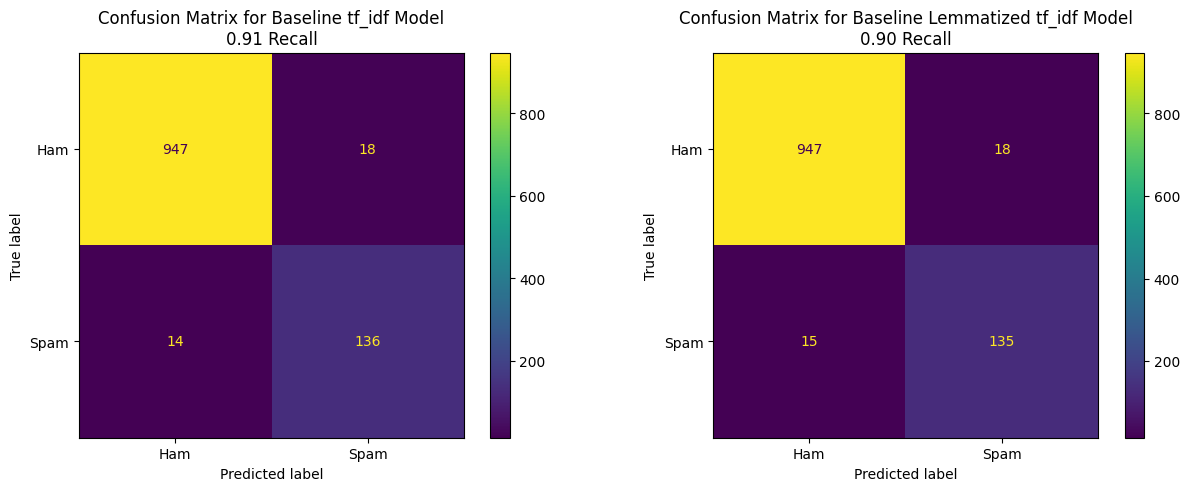

In [25]:
# loading weights
tf_idf_best_params = pd.read_csv('results/tf_idf_results.csv').sort_values(by='f1', ascending=False).iloc[0]
tf_idf_lemmatized_best_params = pd.read_csv('results/lemmatized_tf_idf_results.csv').sort_values(by='f1', ascending=False).iloc[0]
tf_idf_model = LinearModel(
  input_dim=int(tf_idf_best_params['input_dim']),
  hidden_dim=int(tf_idf_best_params['hidden_dim']),
  output_dim=int(tf_idf_best_params['output_dim']),
  dropout_rate=float(tf_idf_best_params['dropout_rate'])
)
tf_idf_lemmatized_model = LinearModel(
  input_dim=int(tf_idf_lemmatized_best_params['input_dim']),
  hidden_dim=int(tf_idf_lemmatized_best_params['hidden_dim']),
  output_dim=int(tf_idf_lemmatized_best_params['output_dim']),
  dropout_rate=float(tf_idf_lemmatized_best_params['dropout_rate'])
)

tf_idf_model.load_state_dict(torch.load('weights/tf_idf_model.pth'))
tf_idf_lemmatized_model.load_state_dict(torch.load('weights/lemmatized_tf_idf_model.pth'))

# get predictions
tf_idf_predictions = tf_idf_model.predict(tf_idf_x_test_loader)
tf_idf_lematized_predictions = tf_idf_lemmatized_model.predict(tf_idf_lematized_x_test_loader)

# plot cms
fig , axes = plt.subplots(1, 2, figsize=(15, 5))

# non lemmatized
tf_idf_cm = confusion_matrix(y_test, tf_idf_predictions)
disp = ConfusionMatrixDisplay(confusion_matrix=tf_idf_cm, display_labels=['Ham', 'Spam'])
disp.plot(ax=axes[0])
axes[0].set_title(f'Confusion Matrix for Baseline tf_idf Model\n{recall_score(y_test, tf_idf_predictions, pos_label=1):.2f} Recall')

# lemmatized
tf_idf_lematized_cm = confusion_matrix(y_test, tf_idf_lematized_predictions)
disp_lematized = ConfusionMatrixDisplay(confusion_matrix=tf_idf_lematized_cm, display_labels=['Ham', 'Spam'])
disp_lematized.plot(ax=axes[1])
axes[1].set_title(f'Confusion Matrix for Baseline Lemmatized tf_idf Model\n{recall_score(y_test, tf_idf_lematized_predictions, pos_label=1):.2f} Recall')

plt.show()

Suprisingly, we see that tf-idf does not perform better than BoW in this case. 


---

## Embedding with GRU, LSTM and BiLSTM

To try to improve performance, we will try to use word embeddings with RNNs such as GRU, LSTM and BiLSTM.

For the Tokenizer, we will be using the `bert-base-uncased` tokenizer from Huggingface.

In [10]:
from transformers import BertTokenizer

tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')

In [11]:
# original
tokenized_train = tokenizer(list(X_train), padding=True, truncation=True, return_tensors='pt')
tokenized_test = tokenizer(list(X_test), padding=True, truncation=True, return_tensors='pt')

tokenized_train_dataset = TensorDataset(tokenized_train['input_ids'], torch.tensor(y_train))
tokenized_train_loader = DataLoader(tokenized_train_dataset, batch_size=32, shuffle=True)

tokenized_test_dataset = TensorDataset(tokenized_test['input_ids'], torch.tensor(y_test))
tokenized_test_loader = DataLoader(tokenized_test_dataset, batch_size=32)

# lemmatized
tokenized_train_lematized = tokenizer(list(X_train_lematized), padding=True, truncation=True, return_tensors='pt')
tokenized_test_lematized = tokenizer(list(X_test_lematized), padding=True, truncation=True, return_tensors='pt')

tokenized_train_lematized_dataset = TensorDataset(tokenized_train_lematized['input_ids'], torch.tensor(y_train))
tokenized_train_lematized_loader = DataLoader(tokenized_train_lematized_dataset, batch_size=32, shuffle=True)

tokenized_test_lematized_dataset = TensorDataset(tokenized_test_lematized['input_ids'], torch.tensor(y_test))
tokenized_test_lematized_loader = DataLoader(tokenized_test_lematized_dataset, batch_size=32)

In [25]:
# define LSTM hyperparameter space
lstm_param_space = {
    'input_dim': [32, 64],
    'hidden_dim': [8, 16, 24, 32],
    'output_dim': [2],
    'lr': [1e-4, 1e-2, 1e-03],
    'batch_size': [16, 32, 64, 128],
    'epochs': [20 , 30], 
    'dropout_rate': [0.3, 0.5, 0.7]
}

lstm_selected_params = list(ParameterSampler(lstm_param_space, n_iter=10, random_state=42))

In [12]:
# we build a simple sequential model as baseline
class LSTM_RNN(Model):
  def __init__(self, input_dim, hidden_dim, output_dim, dropout_rate=0.5):
    super().__init__()
    self.embedding = nn.Embedding(num_embeddings=30522, embedding_dim=input_dim, padding_idx=0)
    # Typically Bi LSTM performs better for text classifications
    self.fc1 = nn.LSTM(input_dim, hidden_dim, batch_first=True, bidirectional=True)
    self.dropout = nn.Dropout(dropout_rate)
    self.fc2 = nn.Linear(hidden_dim * 2, 32) # fully connected layer
    self.relu = nn.ReLU()
    self.fc3 = nn.Linear(32 , output_dim)
  
  def forward(self, x):
    x = self.embedding(x)
    _,  (h_n , _) = self.fc1(x)

    # passing front back
    h_forward = h_n[-2,:,:]
    h_backward = h_n[-1,:,:]

    h = torch.concat((h_forward, h_backward), dim=1)

    out = self.dropout(h)
    out = self.fc2(out)
    out = self.relu(out)
    out = self.fc3(out)
    return out

In [27]:
# Prevent rerunning
# hyperparameter tuning for LSTM models (original and lemmatized)
lstm_results = []
kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
for params in lstm_selected_params:
  print(f"Training LSTM with params: {params}")
  
  model = LSTM_RNN
  optimizer = Adam
  loss_fn = nn.CrossEntropyLoss(weight=class_weights)
  results = train_kf(
    model,
    params={
      'input_dim': params['input_dim'],
      'hidden_dim': params['hidden_dim'],
      'output_dim': params['output_dim'],
      'dropout_rate': params['dropout_rate']
    },
    train_loader=tokenized_train_loader,
    loss_fn=loss_fn,
    optimizer=optimizer,
    kf=kf,
    batch_size=params['batch_size'],
    epochs=params['epochs'],
    early_stop=True,
    patience=3
  )
  
  lstm_results.append({
    **params,
    **results
  })
  
# lemmatized data
lstm_lematized_results = []
for params in lstm_selected_params:
  print(f"Training Lemmatized LSTM with params: {params}")
  model = LSTM_RNN
  optimizer = Adam
  loss_fn = nn.CrossEntropyLoss(weight=class_weights)
  results = train_kf(
    model,
    params={
      'input_dim': params['input_dim'],
      'hidden_dim': params['hidden_dim'],
      'output_dim': params['output_dim'],
      'dropout_rate': params['dropout_rate']
    },
    train_loader=tokenized_train_lematized_loader,
    loss_fn=loss_fn,
    optimizer=optimizer,
    kf=kf,
    batch_size=params['batch_size'],
    epochs=params['epochs'],
    early_stop=True,
    patience=3
  )
  
  lstm_lematized_results.append({
    **params,
    **results
  })

Training LSTM with params: {'output_dim': 2, 'lr': 0.0001, 'input_dim': 32, 'hidden_dim': 32, 'epochs': 30, 'dropout_rate': 0.5, 'batch_size': 32}

Fold 1/5
Epoch 1/30, Loss: 0.6226, Accuracy: 69.46%
Epoch 2/30, Loss: 0.2796, Accuracy: 91.11%
Epoch 3/30, Loss: 0.1889, Accuracy: 94.56%
Epoch 4/30, Loss: 0.1380, Accuracy: 96.83%
Epoch 5/30, Loss: 0.1116, Accuracy: 97.34%
Epoch 6/30, Loss: 0.0880, Accuracy: 98.37%
Epoch 7/30, Loss: 0.0676, Accuracy: 99.07%
Epoch 8/30, Loss: 0.0488, Accuracy: 99.19%
Epoch 9/30, Loss: 0.0605, Accuracy: 98.88%
Epoch 10/30, Loss: 0.0376, Accuracy: 99.27%
Epoch 11/30, Loss: 0.0329, Accuracy: 99.52%
Epoch 12/30, Loss: 0.0274, Accuracy: 99.64%
Epoch 13/30, Loss: 0.0263, Accuracy: 99.64%
Epoch 14/30, Loss: 0.0200, Accuracy: 99.80%
Epoch 15/30, Loss: 0.0133, Accuracy: 99.80%
Epoch 16/30, Loss: 0.0087, Accuracy: 99.66%
Epoch 17/30, Loss: 0.0101, Accuracy: 99.78%
Epoch 18/30, Loss: 0.0504, Accuracy: 99.10%
Epoch 19/30, Loss: 0.0218, Accuracy: 99.36%
Early stopping a

In [28]:
lstm_results_df = pd.DataFrame(lstm_results).sort_values(by='f1', ascending=False)
lstm_lematized_results_df = pd.DataFrame(lstm_lematized_results).sort_values(by='f1', ascending=False)

lstm_results_df.to_csv('results/lstm_results.csv', index=False)
lstm_lematized_results_df.to_csv('results/lemmatized_lstm_results.csv', index=False)

display(lstm_results_df)
display(lstm_lematized_results_df)

,output_dim,lr,input_dim,hidden_dim,epochs,dropout_rate,batch_size,recall,precision,f1,accuracy
8,2,0.0100,64,16,30,0.5,16,0.942053,0.942719,0.942130,0.973081
0,2,0.0001,32,32,30,0.5,32,0.934942,0.938923,0.936559,0.970615
1,2,0.0100,64,32,20,0.7,16,0.935379,0.937179,0.935797,0.970167
4,2,0.0001,32,32,20,0.7,64,0.930502,0.940465,0.935242,0.970168
6,2,0.0100,32,32,20,0.7,32,0.940863,0.927130,0.933635,0.968594
9,2,0.0010,32,32,30,0.5,64,0.931937,0.935380,0.933341,0.969040
7,2,0.0010,64,8,30,0.3,16,0.930313,0.931522,0.930297,0.967471
2,2,0.0100,64,16,20,0.5,64,0.929042,0.932000,0.930234,0.967699
5,2,0.0100,64,24,20,0.7,64,0.935520,0.916579,0.924090,0.962984
3,2,0.0001,32,32,20,0.5,128,0.929977,0.915406,0.922364,0.963209


,output_dim,lr,input_dim,hidden_dim,epochs,dropout_rate,batch_size,recall,precision,f1,accuracy
1,2,0.0100,64,32,20,0.7,16,0.938215,0.958101,0.947709,0.976222
2,2,0.0100,64,16,20,0.5,64,0.930155,0.957952,0.943277,0.974430
8,2,0.0100,64,16,30,0.5,16,0.941377,0.938696,0.939815,0.971960
6,2,0.0100,32,32,20,0.7,32,0.939788,0.935448,0.937090,0.970392
9,2,0.0010,32,32,30,0.5,64,0.942824,0.928479,0.935429,0.969493
0,2,0.0001,32,32,30,0.5,32,0.932347,0.937174,0.934554,0.969720
5,2,0.0100,64,24,20,0.7,64,0.937522,0.927117,0.931821,0.967697
3,2,0.0001,32,32,20,0.5,128,0.933076,0.923513,0.928108,0.966125
7,2,0.0010,64,8,30,0.3,16,0.927869,0.926709,0.926659,0.965682
4,2,0.0001,32,32,20,0.7,64,0.926167,0.924465,0.925187,0.965229


In [29]:
baseline_lstm = LSTM_RNN(input_dim=64, hidden_dim=32, output_dim=2)
lemmatized_baseline_lstm = LSTM_RNN(input_dim=64, hidden_dim=32, output_dim=2)

loss_fn = nn.CrossEntropyLoss(weight=class_weights)
optimizer_lstm = Adam(baseline_lstm.parameters(), lr=1e-03)
lemmatized_optimizer_lstm = Adam(lemmatized_baseline_lstm.parameters(), lr=1e-03)

In [30]:
print('Training Baseline LSTM Model')
with timer('Baseline LSTM Model Training Time'):
  lstm_best_params = lstm_results_df.iloc[0]

  # rebatch with best batch size
  tokenized_train_loader = DataLoader(tokenized_train_dataset, batch_size=int(lstm_best_params['batch_size']), shuffle=True)

  baseline_lstm = LSTM_RNN(
    input_dim=int(lstm_best_params['input_dim']),
    hidden_dim=int(lstm_best_params['hidden_dim']),
    output_dim=int(lstm_best_params['output_dim']),
    dropout_rate=float(lstm_best_params['dropout_rate'])
  )
  optimizer_lstm = Adam(baseline_lstm.parameters(), lr=lstm_best_params['lr'])
  baseline_lstm.fit(int(lstm_best_params['epochs']), tokenized_train_loader, loss_fn, optimizer_lstm, early_stop=True)

print()
print('Training Baseline Lemmatized LSTM Model')
with timer('Baseline Lemmatized LSTM Model Training Time'):
  lstm_lematized_best_params = lstm_lematized_results_df.iloc[0]

  # rebatch with best batch size
  tokenized_train_lematized_loader = DataLoader(tokenized_train_lematized_dataset, batch_size=int(lstm_lematized_best_params['batch_size']), shuffle=True)

  lemmatized_baseline_lstm = LSTM_RNN(
    input_dim=int(lstm_lematized_best_params['input_dim']),
    hidden_dim=int(lstm_lematized_best_params['hidden_dim']),
    output_dim=int(lstm_lematized_best_params['output_dim']),
    dropout_rate=float(lstm_lematized_best_params['dropout_rate'])
  )
  lemmatized_optimizer_lstm = Adam(lemmatized_baseline_lstm.parameters(), lr=lstm_lematized_best_params['lr'])
  lemmatized_baseline_lstm.fit(int(lstm_lematized_best_params['epochs']), tokenized_train_lematized_loader, loss_fn, lemmatized_optimizer_lstm, early_stop=True)

Training Baseline LSTM Model
Epoch 1/30, Loss: 0.4144, Accuracy: 83.24%
Epoch 2/30, Loss: 0.1420, Accuracy: 96.52%
Epoch 3/30, Loss: 0.0756, Accuracy: 98.03%
Epoch 4/30, Loss: 0.0519, Accuracy: 98.83%
Epoch 5/30, Loss: 0.0431, Accuracy: 99.08%
Epoch 6/30, Loss: 0.0445, Accuracy: 98.65%
Epoch 7/30, Loss: 0.0367, Accuracy: 99.30%
Epoch 8/30, Loss: 0.0093, Accuracy: 99.69%
Epoch 9/30, Loss: 0.0028, Accuracy: 99.91%
Epoch 10/30, Loss: 0.0015, Accuracy: 99.96%
Epoch 11/30, Loss: 0.0037, Accuracy: 99.93%
Epoch 12/30, Loss: 0.0020, Accuracy: 99.96%
Epoch 13/30, Loss: 0.0089, Accuracy: 99.80%
Epoch 14/30, Loss: 0.0119, Accuracy: 99.66%
Epoch 15/30, Loss: 0.0026, Accuracy: 99.91%
Early stopping at epoch 15 due to no improvement in validation loss for 5 consecutive epochs.
Baseline LSTM Model Training Time: 156.9218s

Training Baseline Lemmatized LSTM Model
Epoch 1/20, Loss: 0.4319, Accuracy: 82.50%
Epoch 2/20, Loss: 0.1591, Accuracy: 96.81%
Epoch 3/20, Loss: 0.1018, Accuracy: 98.12%
Epoch 4/20,

In [31]:
# saving weights
torch.save(baseline_lstm.state_dict(), 'weights/baseline_lstm_model.pth')
torch.save(lemmatized_baseline_lstm.state_dict(), 'weights/baseline_lemmatized_lstm_model.pth')

In [26]:
# loading weights
lstm_best_params = pd.read_csv('results/lstm_results.csv').sort_values(by='f1', ascending=False).iloc[0]
lstm_lematized_best_params = pd.read_csv('results/lemmatized_lstm_results.csv').sort_values(by='f1', ascending=False).iloc[0]

baseline_lstm = LSTM_RNN(
  input_dim=int(lstm_best_params['input_dim']),
  hidden_dim=int(lstm_best_params['hidden_dim']),
  output_dim=int(lstm_best_params['output_dim']),
  dropout_rate=float(lstm_best_params['dropout_rate'])
)
lemmatized_baseline_lstm = LSTM_RNN(
  input_dim=int(lstm_lematized_best_params['input_dim']),
  hidden_dim=int(lstm_lematized_best_params['hidden_dim']),
  output_dim=int(lstm_lematized_best_params['output_dim']),
  dropout_rate=float(lstm_lematized_best_params['dropout_rate'])
)

baseline_lstm.load_state_dict(torch.load('weights/baseline_lstm_model.pth'))
lemmatized_baseline_lstm.load_state_dict(torch.load('weights/baseline_lemmatized_lstm_model.pth'))

# get predictions
baseline_lstm_predictions = baseline_lstm.predict(tokenized_test_loader)
baseline_lstm_lematized_predictions = lemmatized_baseline_lstm.predict(tokenized_test_lematized_loader)

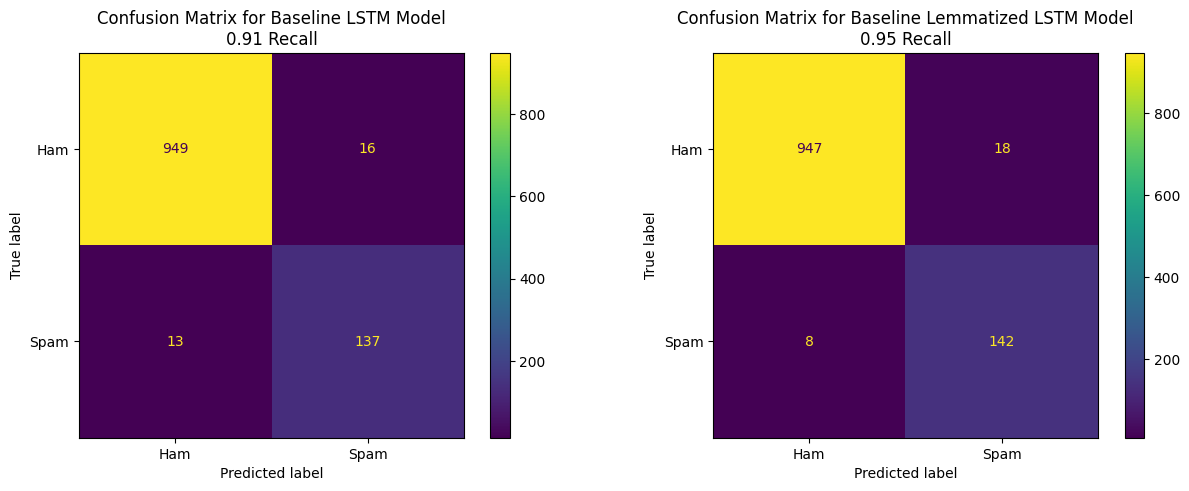

In [27]:
# evaluate baseline LSTM models
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# original
lstm_cm = confusion_matrix(y_test, baseline_lstm_predictions)
disp = ConfusionMatrixDisplay(confusion_matrix=lstm_cm, display_labels=['Ham', 'Spam'])
disp.plot(ax=axes[0])
axes[0].set_title(
    f'Confusion Matrix for Baseline LSTM Model\n{recall_score(y_test, baseline_lstm_predictions, pos_label=1):.2f} Recall'
),

# lemmatized
lstm_lematized_cm = confusion_matrix(y_test, baseline_lstm_lematized_predictions)
disp_lematized = ConfusionMatrixDisplay(confusion_matrix=lstm_lematized_cm, display_labels=['Ham', 'Spam'])
disp_lematized.plot(ax=axes[1])
axes[1].set_title(
    f'Confusion Matrix for Baseline Lemmatized LSTM Model\n{recall_score(y_test, baseline_lstm_lematized_predictions, pos_label=1):.2f} Recall'
),

plt.show()

## Results Comparison

To summarise the results of the variaous models:

|Model|Origianl Data Recall|Original Data Training Time (seconds)|Lemmatized Data Recall|Lemmatized Data Training Time (seconds)|
|-----|--------------------|---------------------|-|-|
|Binary BoW + MLP|0.89|2.04|0.87|3.76|
|TF-IDF + MLP|0.91|2.85|0.9|2.58|
|Embedding + LSTM|0.91|156.92|0.95|138.49|


We see that the simple Binary BoW + MLP model performs quite well. 

TF-IDF is the closest to the performance of the more complex Embedding + LSTM model, while being much faster to train and smaller in size.

**What this can mean?**

1. For spam email detection, simple models like TF-IDF + MLP can be very effective.
2. The data might have some sequential patterns that LSTM can use, but not strong enough to give it a significant advantage over simpler models.
3. Small Dataset size might limit the effectiveness of complex models like LSTM.

### Basic Diagnosis

To further understand,
- we can try **shuffling** the words in the email to see if word order matters.

In [15]:
# word shuffling diagnostic for sequence sensitivity
def shuffle_words(text, rng):
  tokens = str(text).split()
  if len(tokens) <= 1:
    return str(text)
  shuffled = tokens[:]
  rng.shuffle(shuffled)
  return " ".join(shuffled)


In [16]:
# set random seeds
rng_original = random.Random(42)
rng_lemmatized = random.Random(42)

X_test_shuffled = [shuffle_words(text, rng_original) for text in X_test]
X_test_lematized_shuffled = [shuffle_words(text, rng_lemmatized) for text in X_test_lematized]

# tokenize shuffled test sets
tokenized_test_shuffled = tokenizer(list(X_test_shuffled), padding=True, truncation=True, return_tensors='pt')
tokenized_test_lematized_shuffled = tokenizer(list(X_test_lematized_shuffled), padding=True, truncation=True, return_tensors='pt')

tokenized_test_shuffled_dataset = TensorDataset(tokenized_test_shuffled['input_ids'], torch.tensor(y_test))
tokenized_test_shuffled_loader = DataLoader(tokenized_test_shuffled_dataset, batch_size=32)

tokenized_test_lematized_shuffled_dataset = TensorDataset(tokenized_test_lematized_shuffled['input_ids'], torch.tensor(y_test))
tokenized_test_lematized_shuffled_loader = DataLoader(tokenized_test_lematized_shuffled_dataset, batch_size=32)

# ensure baseline predictions are available
if 'baseline_lstm_predictions' not in globals():
  baseline_lstm_predictions = baseline_lstm.predict(tokenized_test_loader)
if 'baseline_lstm_lematized_predictions' not in globals():
  baseline_lstm_lematized_predictions = lemmatized_baseline_lstm.predict(tokenized_test_lematized_loader)

# predictions on shuffled text
baseline_lstm_predictions_shuffled = baseline_lstm.predict(tokenized_test_shuffled_loader)
baseline_lstm_lematized_predictions_shuffled = lemmatized_baseline_lstm.predict(tokenized_test_lematized_shuffled_loader)

In [18]:

# recall comparison
original_recall = recall_score(y_test, baseline_lstm_predictions, pos_label=1)
shuffled_recall = recall_score(y_test, baseline_lstm_predictions_shuffled, pos_label=1)

original_lemmatized_recall = recall_score(y_test, baseline_lstm_lematized_predictions, pos_label=1)
shuffled_lemmatized_recall = recall_score(y_test, baseline_lstm_lematized_predictions_shuffled, pos_label=1)

delta_original = shuffled_recall - original_recall
delta_lemmatized = shuffled_lemmatized_recall - original_lemmatized_recall

print('=== Sequence Sensitivity Check (LSTM) ===')
print(f'Original recall (non-lemmatized):  {original_recall:.4f}')
print(f'Shuffled recall (non-lemmatized):  {shuffled_recall:.4f}')
print(f'Delta (shuffled - original):       {delta_original:+.4f}')
print()
print(f'Original recall (lemmatized):      {original_lemmatized_recall:.4f}')
print(f'Shuffled recall (lemmatized):      {shuffled_lemmatized_recall:.4f}')
print(f'Delta (shuffled - original):       {delta_lemmatized:+.4f}')

=== Sequence Sensitivity Check (LSTM) ===
Original recall (non-lemmatized):  0.9133
Shuffled recall (non-lemmatized):  0.9133
Delta (shuffled - original):       +0.0000

Original recall (lemmatized):      0.9467
Shuffled recall (lemmatized):      0.9400
Delta (shuffled - original):       -0.0067


**Observations:**

- There is minimal changes in the recall, which suggest that there is little dependence on word order for this task. 

## U-Score calculation

With the model's performances, we can now calculate a U-Score to compare the models in a more holistic way, taking into account both performance and efficiency.

We can consider 3 approaches:
- Quality Focused
- Efficiency Focused
- Balanced

the general formula for the U-Score can be defined as:

$$U = \alpha \cdot \text{Recall} - \beta \cdot \text{Training Time} - \gamma \cdot \text{Model Size}$$

In [85]:
# range sweeping for utility function weights
# 3 different sweeps for quality, balanced and efficiency focused.
# we enforce a + b + g = 1 constraint by sampling from a grid and normalizing the weights
weight_combinations = list(ParameterSampler({
    'alpha': np.arange(0.1, 1.1, 0.05),
    'beta': np.arange(0.1, 1.1, 0.05),
    'gamma': np.arange(0.1, 1.1, 0.05)
}, n_iter=1000, random_state=42))

quality_focused = list(ParameterSampler({
    'alpha': np.arange(0.5, 1.1, 0.05),
    'beta': np.arange(0.1, 0.6, 0.05),
    'gamma': np.arange(0.1, 0.6, 0.05)
}, n_iter=300, random_state=42))

balanced = list(ParameterSampler({
    'alpha': np.arange(0.3, 0.8, 0.05),
    'beta': np.arange(0.3, 0.8, 0.05),
    'gamma': np.arange(0.3, 0.8, 0.05)
}, n_iter=300, random_state=42))

efficiency_focused = list(ParameterSampler({
    'alpha': np.arange(0.1, 0.6, 0.05),      
    'beta': np.arange(0.5, 1.1, 0.05),
    'gamma': np.arange(0.5, 1.1, 0.05)
}, n_iter=300, random_state=42))

# model metrics for utility calculation
# we min max norm all
min_max_scaler = lambda x: (x - np.min(x)) / (np.max(x) - np.min(x) + 1e-8)
recalls = min_max_scaler(np.array([
    recall_score(y_test, baseline_bow_predictions, pos_label=1),
    recall_score(y_test, baseline_bow_lematized_predictions, pos_label=1),
    recall_score(y_test, tf_idf_predictions, pos_label=1),
    recall_score(y_test, tf_idf_lematized_predictions, pos_label=1),
    recall_score(y_test, baseline_lstm_predictions, pos_label=1),
    recall_score(y_test, baseline_lstm_lematized_predictions, pos_label=1)
]))

# we log the training times to reduce skew
training_times = min_max_scaler(np.log1p(np.array([2.04, 3.76, 2.85, 2.58, 156.92, 138.49])))
model_sizes = min_max_scaler(np.array([sum(p.numel() for p in bow_best_model.parameters()),
                                      sum(p.numel() for p in lemmatized_bow_best_model.parameters()),
                                      sum(p.numel() for p in tf_idf_model.parameters()),
                                      sum(p.numel() for p in tf_idf_lemmatized_model.parameters()),
                                      sum(p.numel() for p in baseline_lstm.parameters()),
                                      sum(p.numel() for p in lemmatized_baseline_lstm.parameters())]))
model_names = ['BoW Baseline', 'Lemmatized BoW Baseline', 'TF-IDF Baseline', 'Lemmatized TF-IDF Baseline', 'LSTM Baseline', 'Lemmatized LSTM Baseline']

In [86]:
# calculate the u-scores
model_winrates = {model_name: {'global': 0, 'quality': 0, 'balanced': 0, 'efficiency': 0} for model_name in model_names}

# calculate throughout
for n , weight_set in zip(['global', 'quality', 'balanced', 'efficiency'], [weight_combinations, quality_focused, balanced, efficiency_focused]):
  for weights in weight_set:

    # make a + b + g = 1 for interpretability
    weight_sum = weights['alpha'] + weights['beta'] + weights['gamma']
    a , b , g = weights['alpha'] / weight_sum, weights['beta'] / weight_sum, weights['gamma'] / weight_sum

    utility_results = a * recalls - b * training_times - g * model_sizes

    # store
    best_model_idx = np.argmax(utility_results)
    best_model_name = model_names[best_model_idx]
    model_winrates[best_model_name][n] += 1

In [93]:
df = pd.DataFrame(model_winrates) 
# convert to percentages winrate
df.loc['global'] = round(df.loc['global'] / df.loc['global'].sum() * 100, 2) 
df.loc['quality'] = round(df.loc['quality'] / df.loc['quality'].sum() * 100, 2)
df.loc['balanced'] = round(df.loc['balanced'] / df.loc['balanced'].sum() * 100, 2)
df.loc['efficiency'] = round(df.loc['efficiency'] / df.loc['efficiency'].sum() * 100, 2) 
print('=== Model Win Rates by Utility Score by Weighting Focus in Percentages ===')
display(df)

=== Model Win Rates by Utility Score by Weighting Focus in Percentages ===


,BoW Baseline,Lemmatized BoW Baseline,TF-IDF Baseline,Lemmatized TF-IDF Baseline,LSTM Baseline,Lemmatized LSTM Baseline
global,6.3,0,90.90,0,0,2.80
quality,0.0,0,77.67,0,0,22.33
balanced,0.0,0,100.00,0,0,0.00
efficiency,19.0,0,81.00,0,0,0.00


## Conclusion

- We observe that the TF-IDF + MLP model has the highest win rates across all utility perspectives, making it the best overall choice for spam email detection in this case.

- This is consistent with its performance across the 'global' sweep, which suggests that this model is consistently better than the other models across different utility weightings.

**We also acklowedge that**
- For extreme quality focused applications, the LSTM model can be a good choice due to its high recall, but it comes at the cost of efficiency.
- For extreme efficiency focused applications, the Binary BoW + MLP can be a good choice due to its low training time and model size, but it comes at the cost of recall.

**To Conclude:**
While complex models like LSTM can achieve high recall, simpler models like TF-IDF + MLP can provide a better balance of performance and efficiency for spam email detection. Therefore, for practical applications where resources are considered, **simpler models like TF-IDF + MLP can outperform more complex models like LSTM for simple tasks like spam email detection.**